In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow.keras import layers, models

BASE = '/content/drive/MyDrive/slr_project'
os.makedirs(f'{BASE}/models', exist_ok=True)

# Pull features.py from your repo (use %%writefile instead if the repo is private)
!rm -rf /content/repo
!git clone https://github.com/Tenzin-06/sign-language-recognition.git /content/repo
sys.path.append('/content/repo/src')
from features import normalize, SEQ_LEN, N_FEATURES

print(tf.__version__, tf.config.list_physical_devices('GPU'))   # the GPU list should not be empty

Mounted at /content/drive
Cloning into '/content/repo'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 36 (delta 9), reused 29 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 1.95 MiB | 5.39 MiB/s, done.
Resolving deltas: 100% (9/9), done.
2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
actions = np.load(f'{BASE}/actions.npy', allow_pickle=True)
n_classes = len(actions)

def load_raw(split):
    d = np.load(f'{BASE}/processed_{split}.npz', allow_pickle=True)
    return d['X'].astype('float32'), d['y'].astype('int32'), d['signer_ids']

Xr_train, y_train, sg_train = load_raw('train')
Xr_val,   y_val,   sg_val   = load_raw('val')
Xr_test,  y_test,  sg_test  = load_raw('test')

# Normalized versions (shoulder-centered, shoulder-width scaled)
norm_all = lambda X: np.stack([normalize(x) for x in X]).astype('float32')
Xn_train, Xn_val, Xn_test = norm_all(Xr_train), norm_all(Xr_val), norm_all(Xr_test)

oh = lambda y: tf.keras.utils.to_categorical(y, n_classes)
Y_train, Y_val, Y_test = oh(y_train), oh(y_val), oh(y_test)

print(Xn_train.shape, Xn_val.shape, Xn_test.shape)      # (~748, 32, 258), (~165, 32, 258), (~100, 32, 258)
print('NaNs:', np.isnan(Xn_train).sum(), '| classes:', n_classes)

(748, 32, 258) (165, 32, 258) (100, 32, 258)
NaNs: 0 | classes: 100


In [5]:
def build_model(n_classes, units=(64, 128, 64), act='relu', dropout=0.0, dense=(64, 32),
                bidirectional=False, rnn='lstm', lr=1e-3, label_smoothing=0.0,
                input_shape=(SEQ_LEN, N_FEATURES)):
    Rnn = layers.LSTM if rnn == 'lstm' else layers.GRU
    m = models.Sequential([layers.Input(shape=input_shape)])
    for i, u in enumerate(units):
        last = (i == len(units) - 1)
        layer = Rnn(u, return_sequences=not last, activation=act)
        m.add(layers.Bidirectional(layer) if bidirectional else layer)
        if dropout: m.add(layers.Dropout(dropout))
    for d in dense:
        m.add(layers.Dense(d, activation='relu'))
        if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(n_classes, activation='softmax'))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
              metrics=['categorical_accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top5')])
    return m

baseline = build_model(n_classes)
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32, 64)         │        82,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │         3,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,452 (939.27 KB)

 Trainable params: 240,452 (939.27 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
label_map = {g: i for i, g in enumerate(actions)}
json.dump(label_map, open(f'{BASE}/models/label_map.json', 'w'), indent=2)
print(list(label_map.items())[:5])
print('train classes present:', len(np.unique(y_train)), 'of', n_classes)
print('val classes present  :', len(np.unique(y_val)), 'of', n_classes)

[(np.str_('accident'), 0), (np.str_('africa'), 1), (np.str_('all'), 2), (np.str_('apple'), 3), (np.str_('basketball'), 4)]
train classes present: 100 of 100
val classes present  : 89 of 100


In [7]:
# Positions of x, y, z values in the 258-vector (pose has a visibility value every 4th slot)
def coord_indices():
    xs, ys, zs = [], [], []
    for i in range(132):
        [xs, ys, zs, None][i % 4].append(i) if i % 4 < 3 else None
    for i in range(132, 258):
        [xs, ys, zs][(i - 132) % 3].append(i)
    return np.array(xs), np.array(ys), np.array(zs)
XI, YI, ZI = coord_indices()
ALL_COORDS = np.concatenate([XI, YI, ZI])

def augment(seq, rng):
    T = len(seq)
    # 1. time warp: random crop, then resample back to T frames
    a, b = rng.integers(0, 4), T - 1 - rng.integers(0, 4)
    s = seq[np.linspace(a, b, T).astype(int)].copy()
    present = (s != 0)                                     # remember which values are real
    # 2. scale
    s[:, ALL_COORDS] *= rng.uniform(0.9, 1.1)
    # 3. small rotation in the x-y plane
    ang = np.deg2rad(rng.uniform(-10, 10))
    x, y = s[:, XI].copy(), s[:, YI].copy()
    s[:, XI] = x * np.cos(ang) - y * np.sin(ang)
    s[:, YI] = x * np.sin(ang) + y * np.cos(ang)
    # 4. shift
    s[:, XI] += rng.uniform(-0.1, 0.1)
    s[:, YI] += rng.uniform(-0.1, 0.1)
    # 5. noise
    s[:, ALL_COORDS] += rng.normal(0, 0.005, size=(T, len(ALL_COORDS)))
    return (s * present).astype('float32')                 # missing points stay zero

def make_augmented(X, y, copies=4, seed=0):
    rng = np.random.default_rng(seed)
    Xs, ys = [X], [y]
    for _ in range(copies):
        Xs.append(np.stack([augment(x, rng) for x in X])); ys.append(y)
    return np.concatenate(Xs), np.concatenate(ys)

# Quick check: the shape and zeros are preserved
xa = augment(Xn_train[0], np.random.default_rng(0))
print(xa.shape, (xa == 0).mean().round(3), (Xn_train[0] == 0).mean().round(3))

(32, 258) 0.198 0.244


In [12]:
results = []

def train(name, epochs=300, batch_size=32, augment_copies=0, normalized=True,
          feature_slice=None, patience=30, seed=42, verbose=0, **model_kw):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva = (Xn_train, Xn_val) if normalized else (Xr_train, Xr_val)
    ytr = y_train
    if augment_copies:
        Xtr, ytr = make_augmented(Xtr, y_train, copies=augment_copies, seed=seed)
    sl = slice(None) if feature_slice is None else feature_slice
    Xtr, Xva = Xtr[:, :, sl], Xva[:, :, sl]
    model = build_model(n_classes, input_shape=(SEQ_LEN, Xtr.shape[2]), **model_kw)

    ckpt = f'{BASE}/content/ckpt_{name}.keras'
    cbs = [tf.keras.callbacks.EarlyStopping(monitor='val_categorical_accuracy', mode='max',
                                            patience=patience, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-5),
           tf.keras.callbacks.ModelCheckpoint(ckpt, monitor='val_categorical_accuracy', mode='max', save_best_only=True)]
    h = model.fit(Xtr, oh(ytr), validation_data=(Xva, Y_val), epochs=epochs,
                  batch_size=batch_size, callbacks=cbs, verbose=verbose).history
    best = int(np.argmax(h['val_categorical_accuracy']))
    row = dict(name=name, val_top1=round(h['val_categorical_accuracy'][best], 4),
               val_top5=round(h['val_top5'][best], 4), train_top1=round(h['categorical_accuracy'][best], 4),
               best_epoch=best + 1, params=model.count_params(), ckpt=ckpt,
               seed=seed, batch=batch_size, aug=augment_copies, norm=normalized, **model_kw)
    results.append(row)
    pd.DataFrame(results).drop(columns=['ckpt']).to_csv(f'{BASE}/models/experiments.csv', index=False)
    print(f"{name}: val top-1 {row['val_top1']:.3f} | top-5 {row['val_top5']:.3f} | "
          f"train top-1 {row['train_top1']:.3f} | best epoch {best + 1}")
    return model, h

def plot_history(h, title=''):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val'); ax[0].set_title(f'{title} loss'); ax[0].legend()
    ax[1].plot(h['categorical_accuracy'], label='train'); ax[1].plot(h['val_categorical_accuracy'], label='val')
    ax[1].set_title(f'{title} accuracy'); ax[1].legend(); plt.tight_layout(); plt.show()

baseline: val top-1 0.176 | top-5 0.400 | train top-1 0.421 | best epoch 68


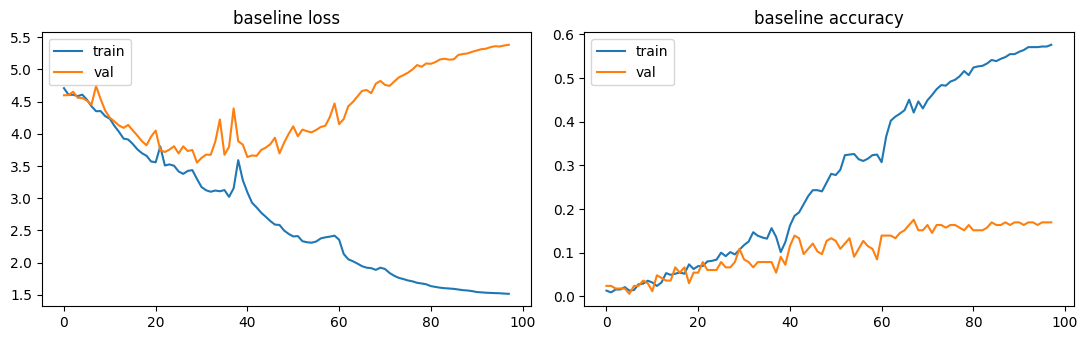

In [11]:
m0, h0 = train('baseline', epochs=200)      # original architecture and settings
plot_history(h0, 'baseline')

In [ ]:
for lr in [3e-4, 1e-3, 3e-3]:
    train(f'lr_{lr}', epochs=200, lr=lr, act='tanh')

for bs in [16, 32, 64]:
    train(f'bs_{bs}', epochs=200, batch_size=bs, act='tanh')

# **Model Optimization**

In [ ]:
# A. cuDNN-friendly activation (tanh), the same size as the baseline
train('A_tanh', epochs=200, act='tanh')

In [ ]:
# B. larger layers + dropout
train('B_tanh_drop', epochs=300, act='tanh', units=(128, 256, 128), dropout=0.3, dense=(128,))

In [ ]:
# C. add augmentation (4 augmented copies of each training video)
train('C_aug', epochs=300, act='tanh', units=(128, 256, 128), dropout=0.3, dense=(128,), augment_copies=4)

In [ ]:
res = pd.DataFrame(results).drop(columns=['ckpt']).sort_values('val_top1', ascending=False)
res[['name', 'val_top1', 'val_top5', 'train_top1', 'best_epoch']]

In [ ]:
base = dict(act='tanh', units=(128, 256, 128), dropout=0.3, dense=(128,), augment_copies=4)

# D. label smoothing
train('D_smooth', epochs=300, label_smoothing=0.1, **base)

In [ ]:
# More variety and stronger regularization
train('H_aug8', epochs=300, **{**base, 'augment_copies': 8})

In [ ]:
train('I_drop5', epochs=300, **{**base, 'dropout': 0.5})

In [ ]:
res = pd.DataFrame(results).drop(columns=['ckpt']).sort_values('val_top1', ascending=False)
res[['name', 'val_top1', 'val_top5', 'train_top1', 'best_epoch']]

In [ ]:
base2 = dict(act='tanh', units=(128, 256, 128), dropout=0.5, dense=(128,), augment_copies=8)

# J. combine H and I
train('J_aug8_drop5', epochs=150, patience=20, **base2)

In [ ]:
# F. hands only (fewer numbers to memorize)
train('F_hands', epochs=150, patience=20, feature_slice=slice(132, 258), **base2)

In [ ]:
# G. check: is normalization really helping?
train('G_no_norm', epochs=150, patience=20, normalized=False, **base2)

In [ ]:
# E. other network types
train('E_gru', epochs=150, patience=20, **{**base2, 'rnn': 'gru'})

In [ ]:
train('E_bilstm', epochs=150, patience=20, **{**base2, 'units': (128, 128), 'bidirectional': True})

In [ ]:
res = pd.DataFrame(results).drop(columns=['ckpt']).sort_values('val_top1', ascending=False)
res[['name', 'val_top1', 'val_top5', 'train_top1', 'best_epoch']]

In [ ]:
final_base = dict(act='tanh', units=(128, 256, 128), dropout=0.5, dense=(128,), augment_copies=8)
train('K_hands_gru', epochs=150, patience=20, feature_slice=slice(132, 258), **{**final_base, 'rnn': 'gru'})

In [ ]:
res = pd.DataFrame(results).drop(columns=['ckpt']).sort_values('val_top1', ascending=False)
res[['name', 'val_top1', 'val_top5', 'train_top1', 'best_epoch']]

In [9]:
!cp /content/drive/MyDrive/slr_project/models/experiments.csv /content/drive/MyDrive/slr_project/models/experiments_backup.csv

In [10]:
BASE = '/content/drive/MyDrive/slr_project'
old = pd.read_csv(f'{BASE}/models/experiments.csv')
results = old.to_dict('records')        # new runs will be added to the old ones
print(len(results), 'old runs loaded')

19 old runs loaded


In [13]:
final_base = dict(act='tanh', units=(128, 256, 128), dropout=0.5, dense=(128,), augment_copies=8)

for s in [1, 2, 3]:
    train(f'final_seed{s}', epochs=150, patience=20, seed=s,
          feature_slice=slice(132, 258), **final_base)

final_seed1: val top-1 0.424 | top-5 0.661 | train top-1 0.987 | best epoch 57
final_seed2: val top-1 0.473 | top-5 0.715 | train top-1 0.976 | best epoch 29
final_seed3: val top-1 0.461 | top-5 0.697 | train top-1 0.986 | best epoch 61


In [14]:
runs = pd.DataFrame([r for r in results if r['name'].startswith('final_seed')])
print(runs[['name', 'val_top1', 'val_top5']])
print(runs[['val_top1', 'val_top5']].agg(['mean', 'std']).round(3))

          name  val_top1  val_top5
0  final_seed1    0.4242    0.6606
1  final_seed2    0.4727    0.7152
2  final_seed3    0.4606    0.6970
      val_top1  val_top5
mean     0.452     0.691
std      0.025     0.028


In [15]:
import shutil, json

best_run = runs.sort_values('val_top1', ascending=False).iloc[0]
print('using', best_run['name'], best_run['val_top1'])
shutil.copy(best_run['ckpt'], f'{BASE}/models/best_model.keras')

config = dict(
    seq_len=SEQ_LEN, n_features=126, feature_slice=[132, 258], normalize=True,
    model=best_run['name'],
    val_top1_mean=round(float(runs['val_top1'].mean()), 4),
    val_top1_std=round(float(runs['val_top1'].std()), 4),
    val_top5_mean=round(float(runs['val_top5'].mean()), 4),
    val_top5_std=round(float(runs['val_top5'].std()), 4))
json.dump(config, open(f'{BASE}/models/model_config.json', 'w'), indent=2)

# Check that it loads and predicts with the right shapes
m = tf.keras.models.load_model(f'{BASE}/models/best_model.keras')
print(m.input_shape)                                          # (None, 32, 126)
print(m.predict(Xn_val[:2, :, 132:258], verbose=0).shape)     # (2, 100)

using final_seed2 0.4727
(None, 32, 126)
(2, 100)
